# 01 — Exploration et nettoyage des données

**Objectif :** comprendre le jeu *Bank Marketing* (UCI), décider comment le nettoyer et repérer ce qui influence la souscription à un dépôt à terme.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Chargement du dataset 

In [2]:
df = pd.read_csv('../data/raw/bank-additional-full.csv', sep=';')

In [3]:
#Identifier les dimensions du DataFrame
print(df.shape)

(41188, 21)


In [4]:
# Types de colonnes et nombre de valeurs non nulles
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [5]:
# Résumé statistique des colonnes numériques (min, max, moyenne, quartiles)
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [6]:
#Afficher les 10 premières lignes du DataFrame
df.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 2. Valeurs manquantes

In [7]:
print("Valeurs nulles (NaN) :", df.isna().sum().sum())

# Ici les valeurs manquantes sont codées par le texte "unknown" : on les compte dans chaque colonne texte
cols_texte = df.select_dtypes(exclude="number").columns
for c in cols_texte:
    n = (df[c] == "unknown").sum()
    if n > 0:
        print(c, ":", n, "unknown")

Valeurs nulles (NaN) : 0
job : 330 unknown
marital : 80 unknown
education : 1731 unknown
default : 8597 unknown
housing : 990 unknown
loan : 990 unknown


**Réponse :** aucune valeur nulle (`NaN`), mais six colonnes contiennent des `unknown` : `default` (8 597), `education` (1 731), `housing` et `loan` (990 chacune), `job` (330) et `marital` (80). On les garde comme une catégorie à part

### 2.1 Doublons

In [8]:
# Compter les lignes dupliquées 
df.duplicated().value_counts()

False    41176
True        12
Name: count, dtype: int64

In [9]:
#Afficher les 10 premières lignes des valeurs dupliquées
print(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

       age         job  marital            education default housing loan  \
28476   24    services   single          high.school      no     yes   no   
28477   24    services   single          high.school      no     yes   no   
14155   27  technician   single  professional.course      no      no   no   
14234   27  technician   single  professional.course      no      no   no   
18464   32  technician   single  professional.course      no     yes   no   
18465   32  technician   single  professional.course      no     yes   no   
32505   35      admin.  married    university.degree      no     yes   no   
32516   35      admin.  married    university.degree      no     yes   no   
12260   36     retired  married              unknown      no      no   no   
12261   36     retired  married              unknown      no      no   no   

         contact month day_of_week  ...  campaign  pdays  previous  \
28476   cellular   apr         tue  ...         1    999         0   
28477   cell

### 2.2 La cible (y) est-elle équilibrée ?

In [10]:
# Nombre et proportion de "no" et de "yes" dans la cible
print(df['y'].value_counts())
print(df["y"].value_counts(normalize=True))

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


**Réponse :** non. La classe majoritaire « no » représente 88,7 % des clients contre 11,3 % de « yes » : le jeu est **déséquilibré**, donc l'exactitude (accuracy) seule serait trompeuse.

## 3. Nettoyage et transformations

Chaque décision est justifiée dans `docs/notes.md`.

#### 3.1 Créer une copie de données 

In [11]:
df_copie = df.copy()

In [12]:
#Supprimer les doublons
df_copie = df_copie.drop_duplicates().reset_index(drop=True)

In [13]:
# Vérifier le nombre de lignes après suppression
print(df_copie.shape)

(41176, 21)


### 3.2 La colonne `duration` (fuite de données)

In [14]:
#Supprimer la colonne "duration" du DataFrame
#df_copie = df_copie.drop(columns=["duration"])

### 3.3 La cible en version numérique

In [14]:
# Creer une nouvelle colonne "y_num" qui convertit la colonne "y" en valeurs numériques (1 pour "yes", 0 pour "no")
# sert à calculer des taux de souscription (moyenne de 0/1)
df_copie["y_num"] = (df_copie["y"] == "yes").astype(int)

### 3.4 Les colonnes `pdays`, `previous` et `poutcome`

`pdays = 999` veut dire « pas de valeur », ce qui n'est pas la même chose que « jamais contacté ». On crée donc deux variables plus fiables : `deja_contacte` et `pdays_jours`.

In [15]:
# proportion des lignes avec pdays == 999 (96,3 %). 
# 999 = "pas de valeur", pas forcément "jamais contacté"
print("Proportion de lignes avec pdays == 999 :", (df_copie["pdays"] == 999).mean())

# Part des clients réellement jamais contactés (previous == 0) : environ 86,3 %
print("Proportion de clients jamais contactés :", (df_copie["previous"] == 0).mean())

Proportion de lignes avec pdays == 999 : 0.9632067223625412
Proportion de clients jamais contactés : 0.8633912959005245


In [16]:
# Combien de clients ont été recontactés le jour même de leur contact précédent (pdays == 0) : très peu
print((df_copie["pdays"] == 0).sum())
print((df_copie["pdays"] == 0).mean())

15
0.0003642898775986011


In [17]:
# Créer "deja_contacte" : 1 si le client a eu au moins un contact avant cette campagne (previous > 0), sinon 0
df_copie["deja_contacte"] = (df_copie["previous"] > 0).astype(int)

In [18]:
# Créer "pdays_jours" : nombre de jours depuis le dernier contact, et -1 quand pdays vaut 999 (délai inconnu ou jamais contacté)
# On utilise -1 et pas 0, car la valeur 0 existe vraiment (contact le jour même)
df_copie["pdays_jours"] = df_copie["pdays"].where(df_copie["pdays"] != 999, -1)

In [19]:
# Contrôle : previous et poutcome disent la même chose (déjà contacté <=> poutcome différent de "nonexistent")
# Si ce n'est pas le cas, assert arrête le notebook avec une erreur
assert ((df_copie["previous"] > 0) == (df_copie["poutcome"] != "nonexistent")).all()
print("OK : previous et poutcome sont cohérents")

OK : previous et poutcome sont cohérents


In [20]:
# Supprimer l'ancienne colonne "pdays", remplacée par deja_contacte et pdays_jours
df_copie = df_copie.drop(columns=["pdays"])

In [21]:
df_copie.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,y_num,deja_contacte,pdays_jours
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,0,-1


In [22]:
# Afficher la table de contingence entre les colonnes "deja_contacte" et "previous"
print(pd.crosstab(df_copie["deja_contacte"], df_copie["previous"]))

previous           0     1    2    3   4   5  6  7
deja_contacte                                     
0              35551     0    0    0   0   0  0  0
1                  0  4561  754  216  70  18  5  1


In [23]:
# Table de contingence deja_contacte x (pdays_jours == -1) : les 4 110 clients "déjà contactés" avec -1
# ont été contactés, mais le délai n'est pas connu. Donc -1 mélange deux cas : jamais contacté et délai inconnu
print(pd.crosstab(df_copie["deja_contacte"], df_copie["pdays_jours"] == -1))

pdays_jours    False  True 
deja_contacte              
0                  0  35551
1               1515   4110


### 3.5 `housing` et `loan`

In [24]:
# housing et loan ont chacun 990 "unknown" : sont-ils manquants sur exactement les mêmes clients ?
mask = df_copie["housing"] == "unknown"
print((mask == (df_copie["loan"] == "unknown")).all()) 

True


### 3.6 `default` : une modalité trop rare

In [25]:
# combien de clients par catégorie
print(df_copie["default"].value_counts()) 
# % de souscription par catégorie  
print("Taux de souscription par catégorie :")
print(df_copie.groupby("default")["y_num"].mean().round(3))   

default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64
Taux de souscription par catégorie :
default
no         0.129
unknown    0.052
yes        0.000
Name: y_num, dtype: float64


In [26]:
# Regrouper "yes" (3 clients seulement) avec "no" : une catégorie aussi petite est inutilisable par un modèle
# On garde "unknown" (20,9 % des clients) : son taux de souscription (5 %) diffère de celui de "no" (13 %), donc elle apporte de l'information
df_copie["default"] = df_copie["default"].replace({"yes": "no"})
print(df_copie["default"].value_counts())

default
no         32580
unknown     8596
Name: count, dtype: int64


### 3.7 `education` : une modalité trop rare

In [27]:
# Afficher la distribution des niveaux d’éducation
print(df_copie["education"].value_counts())
# Fusionner "illiterate" (18 clients) avec "basic.4y" (niveau le plus proche), puis réafficher
df_copie["education"] = df_copie["education"].replace({"illiterate": "basic.4y"})
print(df_copie["education"].value_counts()) 

education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4194
basic.6y                2291
unknown                 1730
Name: count, dtype: int64


### 3.8 `campaign` : valeurs extrêmes

In [28]:
# Ranger chaque client dans une tranche de nombre de contacts, puis calculer le taux de souscription de chaque tranche
# Le taux chute de 13 % (1 contact) à 0,6 % (plus de 20) : les valeurs extrêmes ne sont pas des erreurs, on garde les lignes
tranches = pd.cut(df_copie["campaign"], bins=[0, 1, 3, 5, 10, 20, 100],
                  labels=["1", "2-3", "4-5", "6-10", "11-20", ">20"])
print(df_copie.groupby(tranches, observed=True)["y_num"].mean().round(3))

campaign
1        0.130
2-3      0.112
4-5      0.087
6-10     0.063
11-20    0.037
>20      0.006
Name: y_num, dtype: float64


In [29]:
# Créer "campaign_plafonnee" : remplace toute valeur supérieure à 20 par 20. Pourquoi : la régression logistique 
# est sensible aux valeurs extrêmes (une valeur à 56 pèse trop). On garde "campaign" intacte pour XGBoost
df_copie["campaign_plafonnee"] = df_copie["campaign"].clip(upper=20)

### 3.9 Les clients de plus de 80 ans

In [30]:
# Les âges élevés sont-ils des erreurs ? On regarde combien ils sont, leur métier et leur taux de souscription
# Résultat : 119 clients, surtout retraités (cohérent), avec un taux de souscription d'environ 50 %
p80 = df_copie[df_copie["age"] > 80]
print(len(p80))
print(p80["job"].value_counts())
print(round(p80["y_num"].mean(), 3))

119
job
retired      105
housemaid     12
unknown        2
Name: count, dtype: int64
0.496


# 4. Exploration des données 

In [31]:
# définir le style de seaborn et calculer le taux global de souscription
sns.set_theme(style="whitegrid")
taux_global = df_copie["y_num"].mean()

y
no     0.887
yes    0.113
Name: proportion, dtype: float64


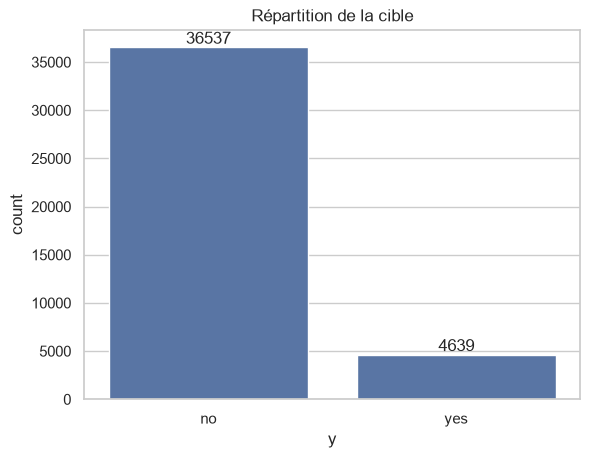

In [36]:
# Diagramme en barres du nombre de "no" et de "yes" : montre le déséquilibre de la cible
print(df_copie["y"].value_counts(normalize=True).round(3))
ax = sns.countplot(data=df_copie, x="y")
for c in ax.containers:
    ax.bar_label(c)
plt.title("Répartition de la cible")
plt.show()

### 4.2 Distribution des variables numériques

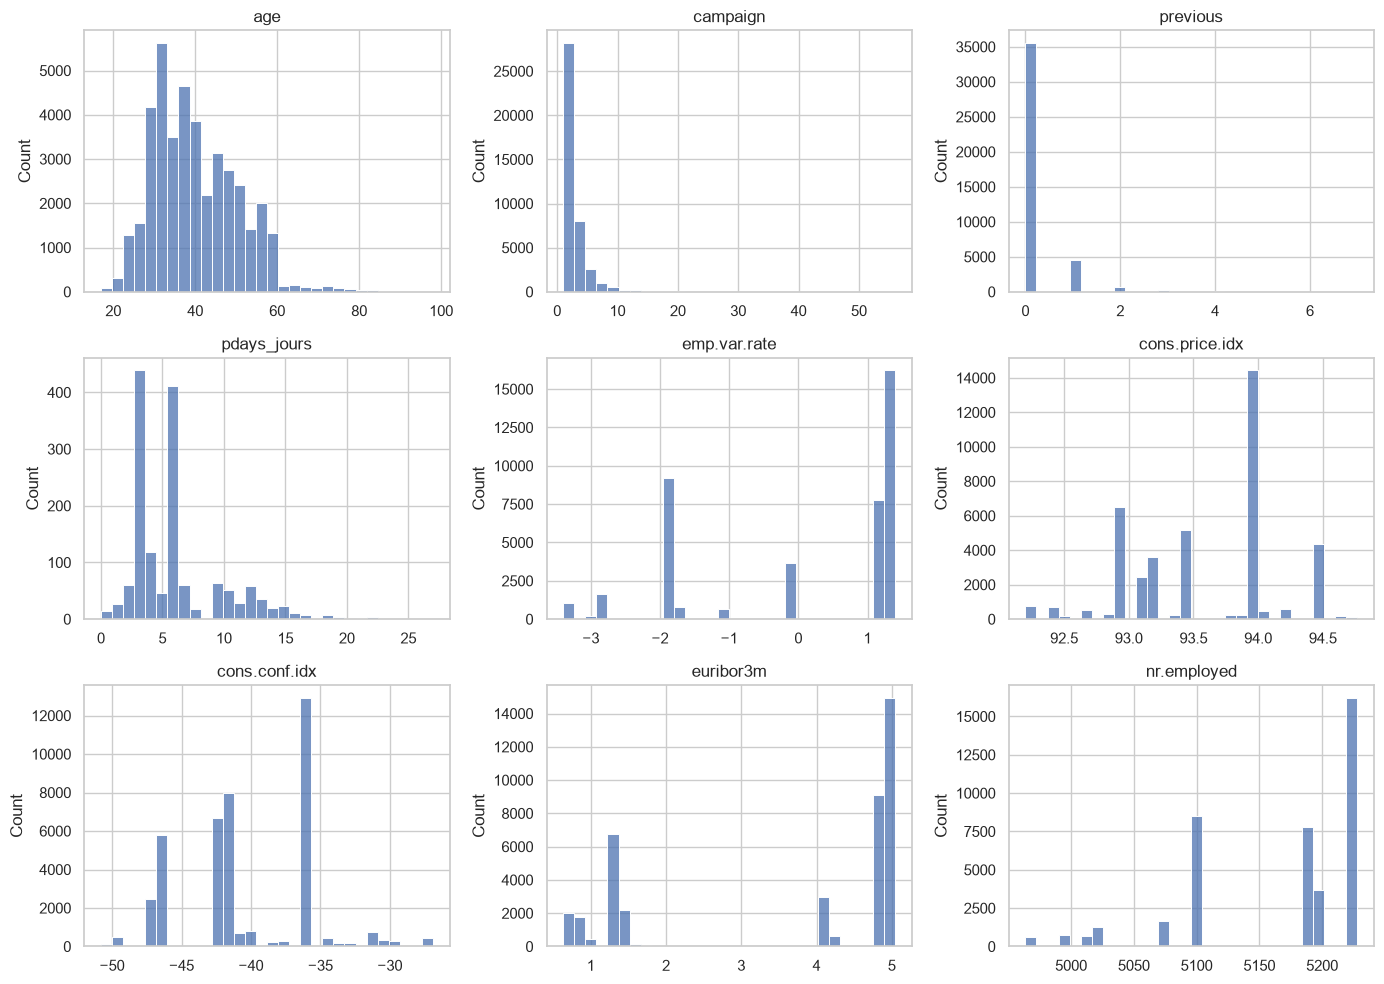

In [37]:
# Histogramme de chaque variable numérique : montre la forme (symétrique, asymétrique, valeurs répétées)
num_cols = ["age", "campaign", "previous", "pdays_jours",
            "emp.var.rate", "cons.price.idx", "cons.conf.idx",
            "euribor3m", "nr.employed"]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), num_cols):
    if col == "pdays_jours":
        data = df_copie.loc[df_copie["pdays_jours"] >= 0, col]   # sans les -1
    else:
        data = df_copie[col]
    sns.histplot(data, bins=30, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 4.3 Distribution des variables catégorielles

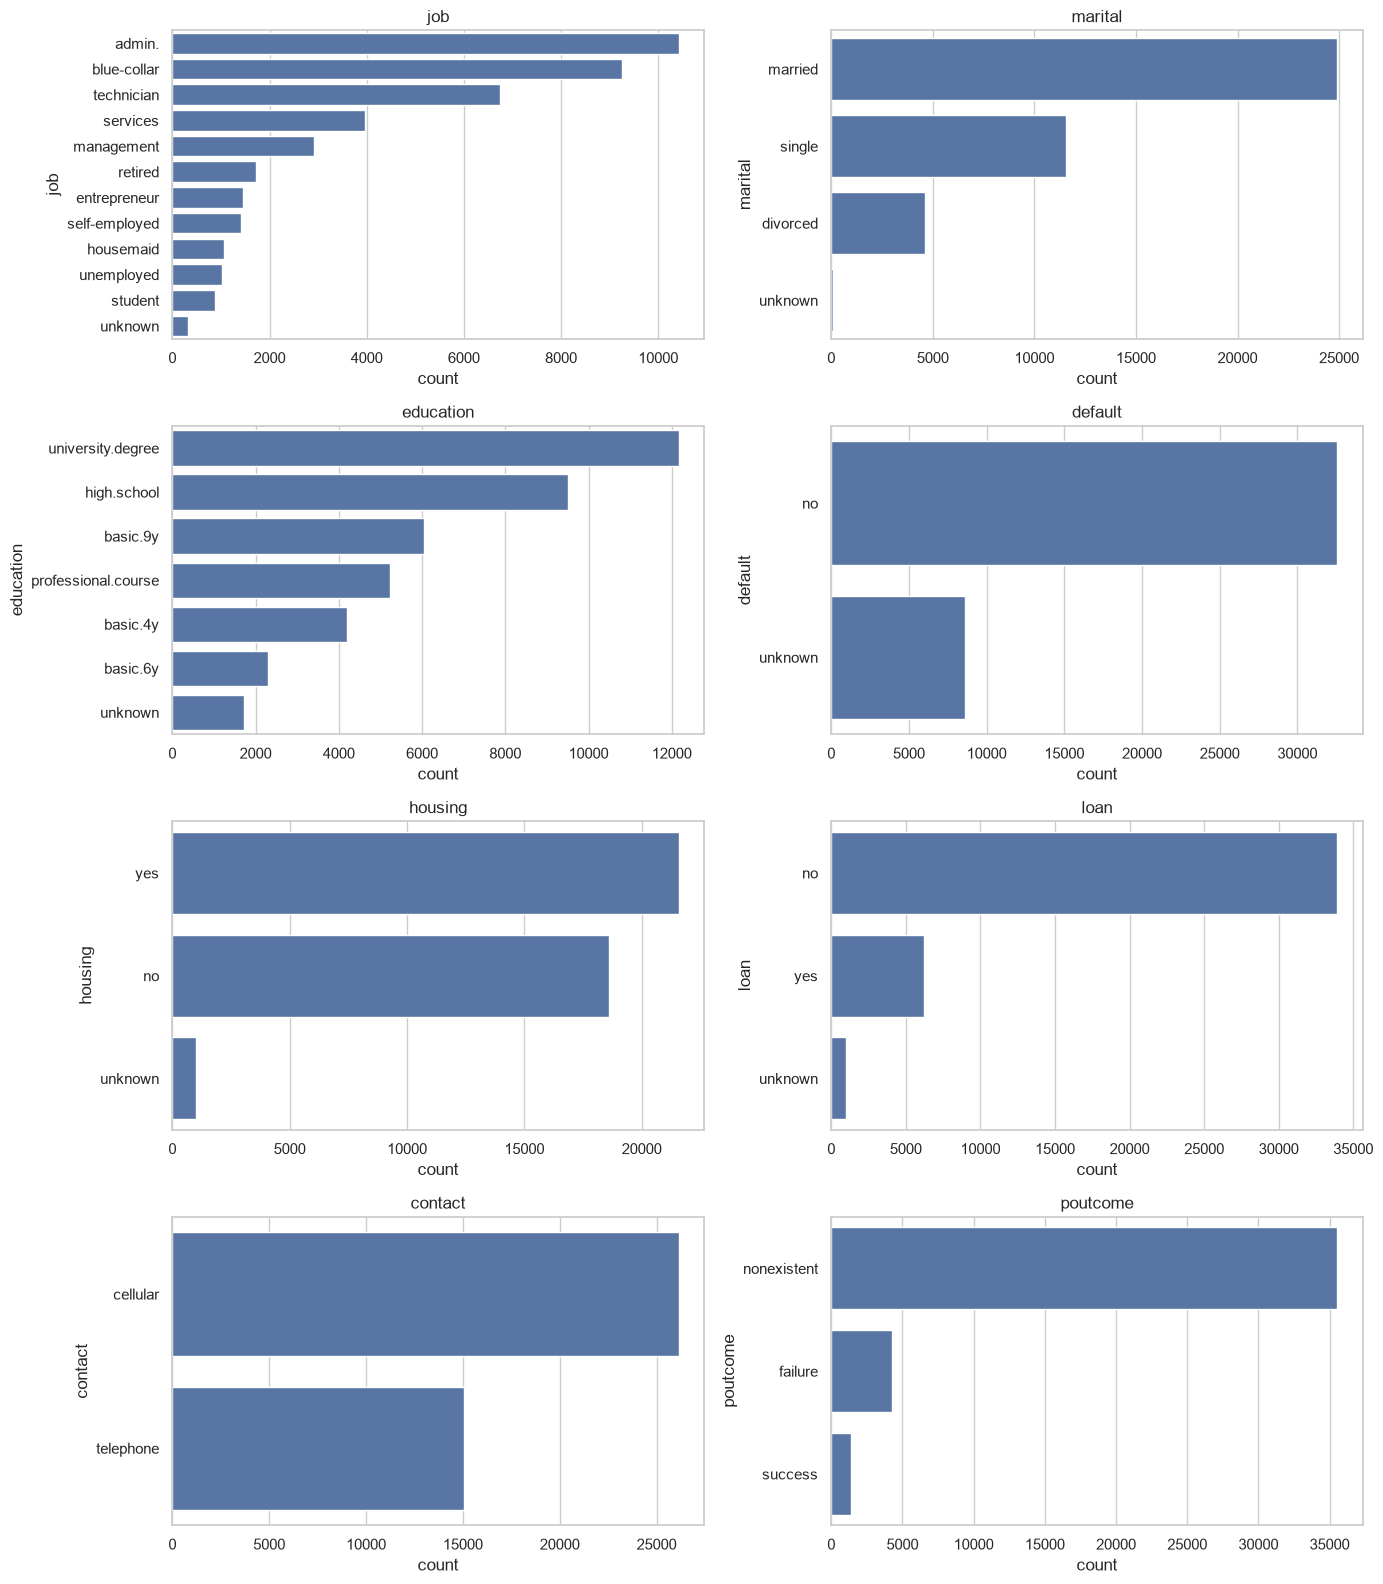

In [38]:
# Nombre de clients par catégorie, triées de la plus fréquente à la moins fréquente : repère les catégories rares
cat_cols = ["job", "marital", "education", "default",
            "housing", "loan", "contact", "poutcome"]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df_copie, y=col,
                  order=df_copie[col].value_counts().index, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 4.4 Taux de souscription par catégorie

C'est la partie la plus utile : on voit **quels groupes de clients souscrivent plus ou moins que la moyenne**. On affiche aussi l'effectif `n` de chaque groupe, car un taux calculé sur très peu de clients est peu fiable.

In [39]:
# Fonction réutilisable : trace le taux de souscription de chaque catégorie, avec la moyenne globale en ligne rouge
# et l'effectif (n) écrit à côté de chaque barre
#   groupe : nom d'une colonne, ou une série (par exemple des tranches d'âge)
#   titre  : titre du graphique
#   ordre  : ordre voulu des catégories (sinon triées par taux décroissant)
def graphique_taux(groupe, titre, ordre=None):
    t = df_copie.groupby(groupe, observed=True)["y_num"].agg(taux="mean", n="size")
    t = t.loc[ordre] if ordre is not None else t.sort_values("taux", ascending=False)

    fig, ax = plt.subplots(figsize=(9, 0.45 * len(t) + 1.5))
    ax.barh(t.index.astype(str), t["taux"] * 100)
    ax.axvline(taux_global * 100, color="red", linestyle="--",
               label=f"moyenne globale ({taux_global:.1%})")
    for i, (taux, n) in enumerate(zip(t["taux"], t["n"])):
        ax.text(taux * 100 + 0.5, i, f"{taux:.1%} (n={n})", va="center")
    ax.invert_yaxis()
    ax.set_xlabel("Taux de souscription (%)")
    ax.set_title(titre)
    ax.set_xlim(0, t["taux"].max() * 100 * 1.3)
    ax.legend(loc="lower right")
    plt.tight_layout()
    return t

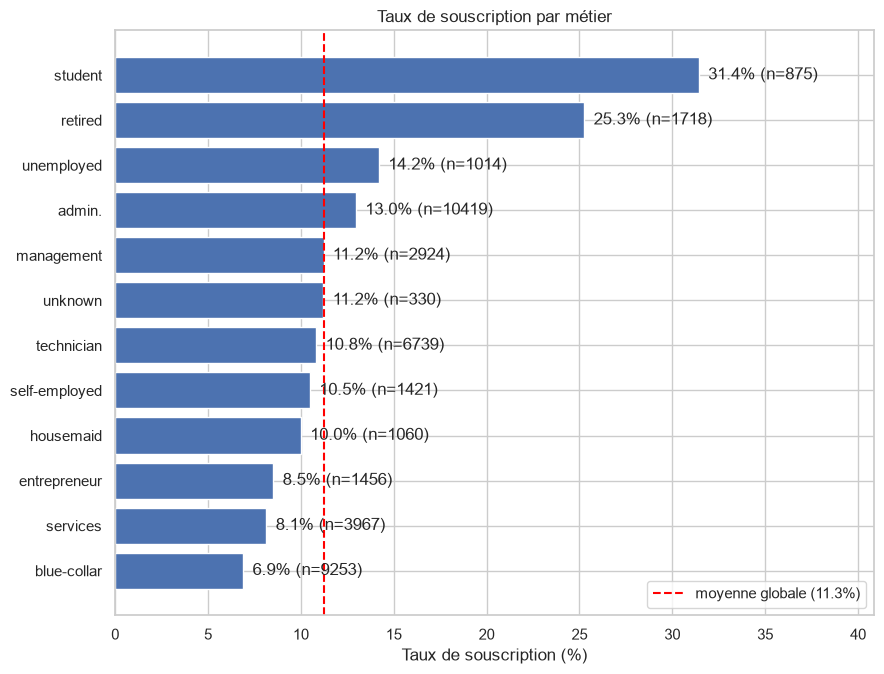

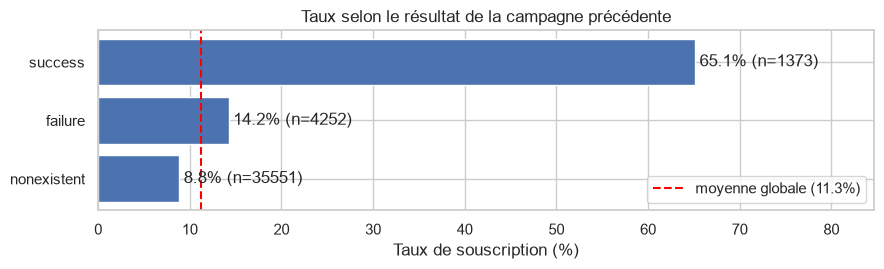

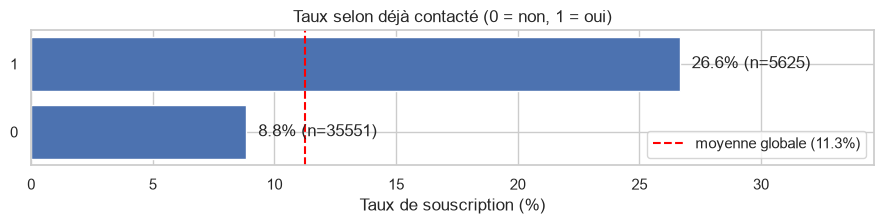

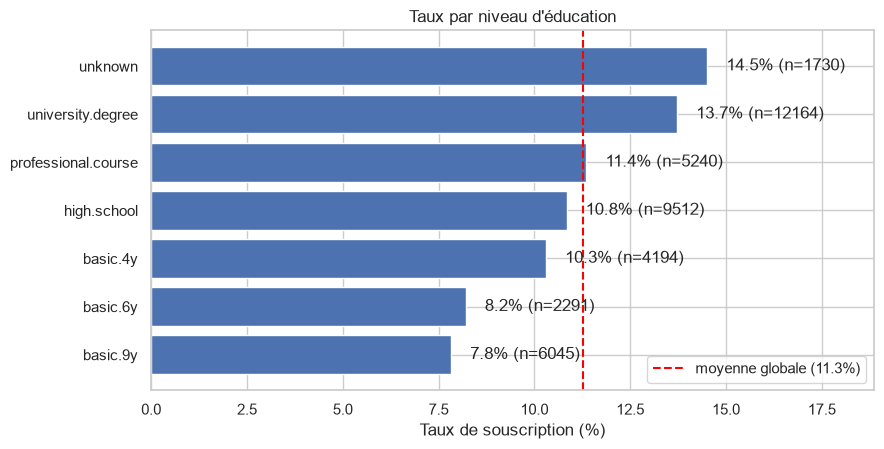

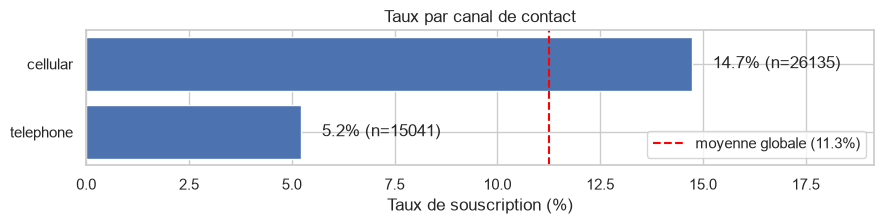

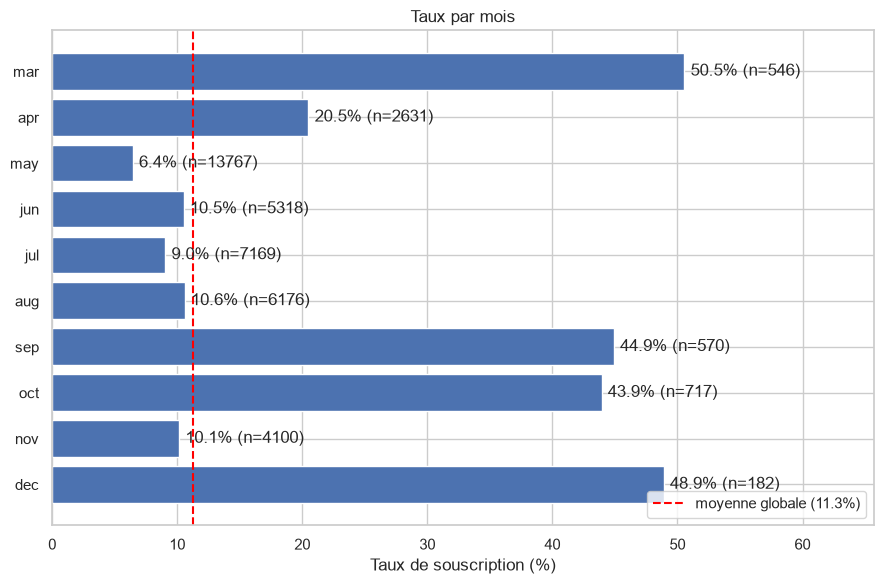

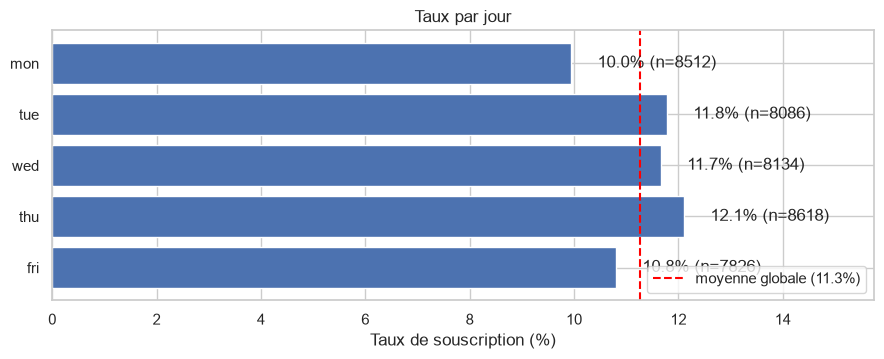

In [40]:
# Appliquer la fonction aux variables catégorielles importantes
graphique_taux("job", "Taux de souscription par métier");                 plt.show()
graphique_taux("poutcome", "Taux selon le résultat de la campagne précédente"); plt.show()
graphique_taux("deja_contacte", "Taux selon déjà contacté (0 = non, 1 = oui)"); plt.show()
graphique_taux("education", "Taux par niveau d'éducation");                plt.show()
graphique_taux("contact", "Taux par canal de contact");                    plt.show()

mois_ordre = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
graphique_taux("month", "Taux par mois", mois_ordre);                      plt.show()
graphique_taux("day_of_week", "Taux par jour", ["mon", "tue", "wed", "thu", "fri"]); plt.show()

### 4.5 Taux de souscription selon l'âge

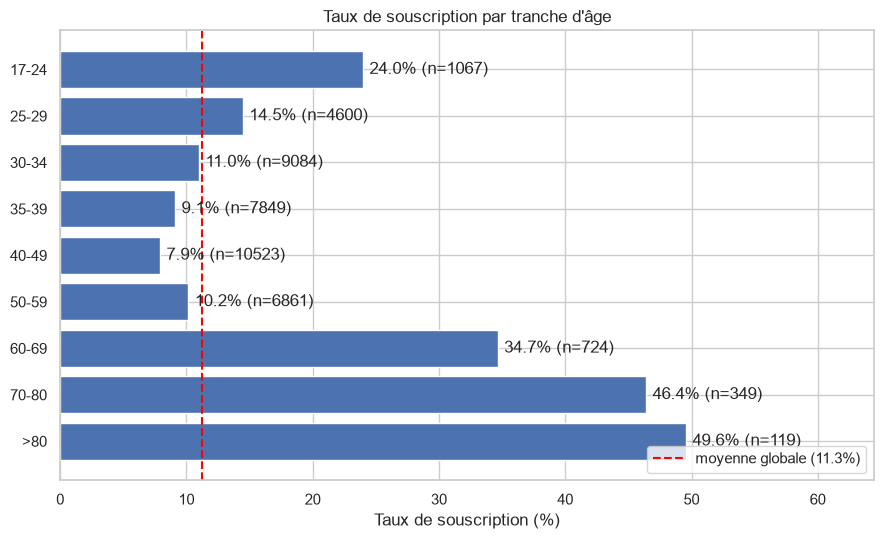

In [41]:
# L'âge brut a trop de valeurs (17 à 98) : on le range en tranches pour voir la forme de la relation
# Résultat attendu : une courbe en U (jeunes et personnes âgées souscrivent plus que les 30-50 ans)
tranche_age = pd.cut(df_copie["age"],
                     bins=[16, 24, 29, 34, 39, 49, 59, 69, 80, 100],
                     labels=["17-24", "25-29", "30-34", "35-39", "40-49",
                             "50-59", "60-69", "70-80", ">80"])
graphique_taux(tranche_age, "Taux de souscription par tranche d'âge",
               ordre=list(tranche_age.cat.categories))
plt.show()

### 4.6 Corrélations entre variables numériques

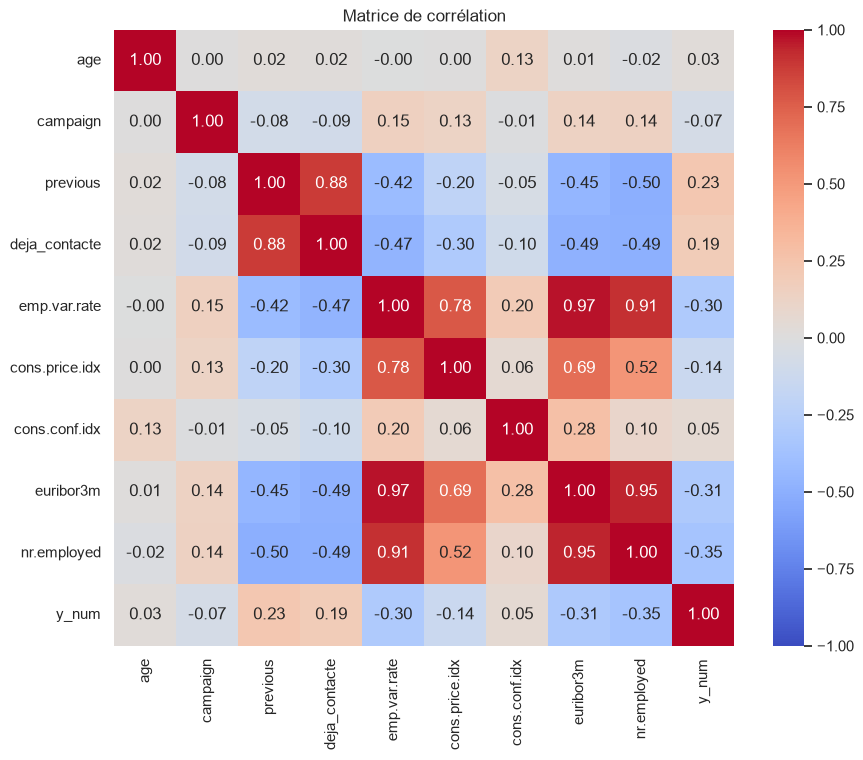

nr.employed      -0.35
euribor3m        -0.31
emp.var.rate     -0.30
cons.price.idx   -0.14
campaign         -0.07
age               0.03
cons.conf.idx     0.05
deja_contacte     0.19
previous          0.23
y_num             1.00
Name: y_num, dtype: float64


In [42]:
# Matrice de corrélation (de -1 à +1) : repère les variables redondantes (macro-économiques) et celles liées à la cible
# Limite : ne détecte que les relations "en ligne droite" (l'âge a une corrélation proche de 0 mais une relation en U)
# pdays_jours est exclue : son code -1 fausserait le calcul
cols_corr = ["age", "campaign", "previous", "deja_contacte",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx",
             "euribor3m", "nr.employed", "y_num"]

corr = df_copie[cols_corr].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

# Corrélation de chaque variable avec la cible, de la plus négative à la plus positive
print(corr["y_num"].sort_values().round(2))

## 5. Analyse temporelle

Le fichier est trié par date (documentation UCI), de mai 2008 à novembre 2010, mais il ne contient que le **mois**, pas l'année. On reconstruit l'année : à chaque fois que le numéro du mois diminue d'une ligne à l'autre (décembre → mars), on est passé à l'année suivante.

C'est une **hypothèse** (fichier supposé trié). Elle est cohérente avec les données : on observe exactement deux retours en arrière.

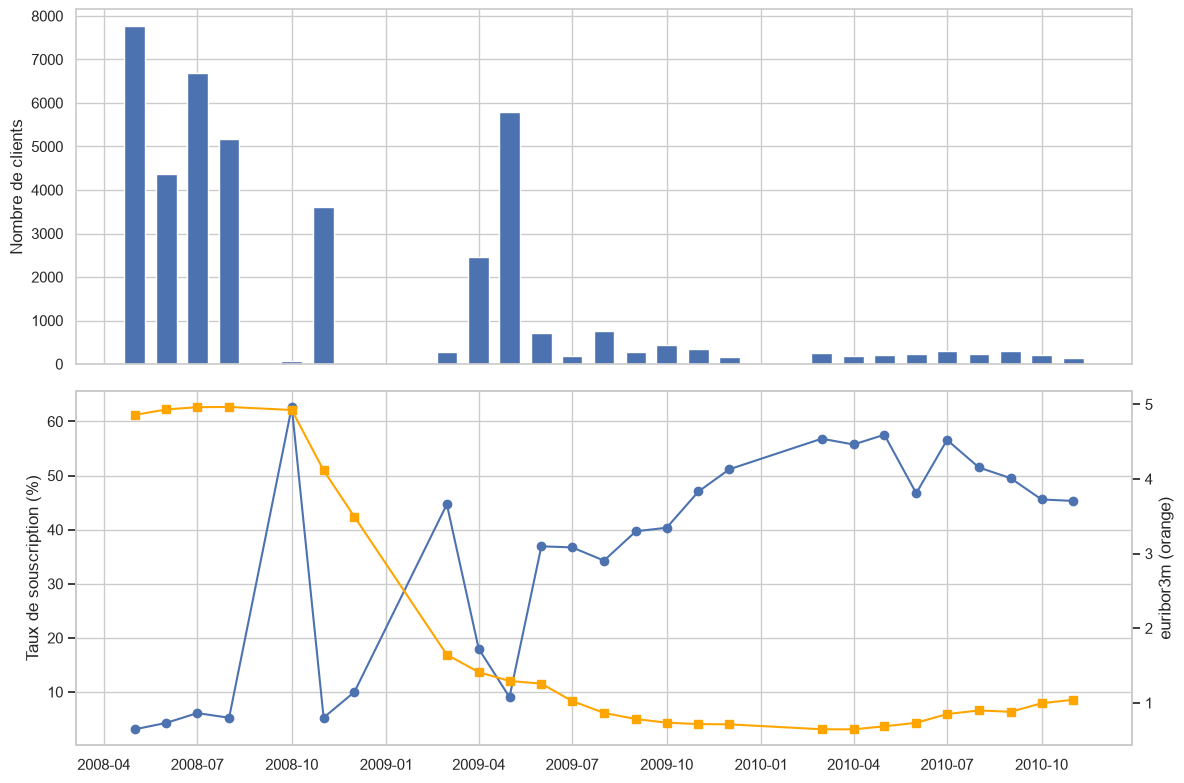

        mean   size
annee              
2008   0.048  27682
2009   0.195  11436
2010   0.521   2058


In [43]:
mois_num = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
            "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12}
m = df_copie["month"].map(mois_num)

temps = pd.DataFrame({"mois": m,
                      "annee": 2008 + (m < m.shift()).cumsum()})
temps["periode"] = pd.to_datetime(dict(year=temps["annee"], month=temps["mois"], day=1))

par_periode = df_copie.groupby(temps["periode"]).agg(
    n=("y_num", "size"),
    taux=("y_num", "mean"),
    euribor3m=("euribor3m", "mean"))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
a1.bar(par_periode.index, par_periode["n"], width=20)
a1.set_ylabel("Nombre de clients")
a2.plot(par_periode.index, par_periode["taux"] * 100, marker="o")
a2.set_ylabel("Taux de souscription (%)")
a3 = a2.twinx()
a3.plot(par_periode.index, par_periode["euribor3m"], color="orange", marker="s")
a3.set_ylabel("euribor3m (orange)")
a3.grid(False)
plt.tight_layout()
plt.show()

print(df_copie.groupby(temps["annee"])["y_num"].agg(["mean", "size"]).round(3))

In [45]:
# Sauvgarder les données pretes
df_copie.to_csv("../data/clean/processed_data.csv", index=False)